# Partie 2 — Regroupement : Trouver l'Origine des Anomalies

## Objectif
```
Après avoir DÉTECTÉ les anomalies dans la Partie 1,
on cherche maintenant à répondre à 2 questions :

  QUESTION 1 : Quelle est la CAUSE de l'anomalie ?
               → Problème technique (puissance hors norme) ?
               → Problème administratif (suspension, statut) ?

  QUESTION 2 : OÙ se trouve l'anomalie ?
               → Sur quelle carte OLT ?
               → Sur quel port ?
               → Pour quel ONU (abonné) ?
```

---
## 1. Imports et Chargement des données

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  

import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.cluster       import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics       import silhouette_score
from sklearn.decomposition import PCA

sns.set(style='whitegrid')
%matplotlib inline

df = pd.read_excel('dataset_ml.xlsx')

# Synchro avec les 721 anomalies du pipeline Z-Score + Rules
if os.path.exists('y_final_z.pkl'):
    y_final_z = joblib.load('y_final_z.pkl')
    df['Anomalie'] = y_final_z
    print("Anomalies synchronisées avec y_final_z.pkl (Z-Score + Rules)")

print(f"Dataset : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"Anomalies : {df['Anomalie'].sum()} ({df['Anomalie'].mean()*100:.1f}%)")
print(f"Normaux   : {(df['Anomalie']==0).sum()} ({(df['Anomalie']==0).mean()*100:.1f}%)")

Anomalies synchronisées avec y_final_z.pkl (Z-Score + Rules)
Dataset : 6692 lignes x 19 colonnes
Anomalies : 721 (10.8%)
Normaux   : 5971 (89.2%)


---
## PARTIE A — Classifier les Anomalies par Cause

### Principe
```
On utilise les 5 règles métier pour étiqueter chaque anomalie.
```

In [2]:
df_anom = df[df['Anomalie'] == 1].copy().reset_index(drop=True)

print(f"Nombre total d'anomalies : {len(df_anom)}")

def classifier_cause(row):
    causes = []

    if row['Etat_OLT_TX'] == 1:
        if row['OLT_POWER_TX'] < 2:
            causes.append('OLT_TX faible')
        else:
            causes.append('OLT_TX elevee')

    if row['Etat_OLT_RX'] == 1:
        if row['OLT_RX_ONT_POWER'] < -32:
            causes.append('OLT_RX faible')
        else:
            causes.append('OLT_RX elevee')

    if row['Etat_ONU_TX'] == 1:
        if row['ONU_POWER_TX'] < 2:
            causes.append('ONU_TX faible')
        else:
            causes.append('ONU_TX elevee')

    if row['Etat_ONU_RX'] == 1:
        if row['ONU_POWER_RX'] < -28:
            causes.append('ONU_RX faible')
        else:
            causes.append('ONU_RX elevee')

    # Cause administrative (Règle 5)
    if row['F_SUSP'] == 1 and row['ADMIN_STATUS'] == 1:
        causes.append('ligne suspendue + port actif')

    if row['ADMIN_STATUS'] == 0 and row['OPER_STATUS'] == 1:
        causes.append('Incoherence: port desactive mais online')

    if not causes:
        return 'Autre'
    return ' + '.join(causes)

df_anom['Cause'] = df_anom.apply(classifier_cause, axis=1)

# Résumé des causes
print("\n=== DISTRIBUTION DES CAUSES ===")
cause_counts = df_anom['Cause'].value_counts()
for cause, count in cause_counts.items():
    pct = count / len(df_anom) * 100
    print(f"  {cause:<45} : {count:3d} ({pct:.1f}%)")

Nombre total d'anomalies : 721

=== DISTRIBUTION DES CAUSES ===
  ONU_RX faible                                 : 230 (31.9%)
  OLT_RX elevee                                 : 169 (23.4%)
  Autre                                         : 102 (14.1%)
  ONU_TX faible                                 :  90 (12.5%)
  OLT_RX faible                                 :  50 (6.9%)
  OLT_RX faible + ONU_RX faible                 :  34 (4.7%)
  Incoherence: port desactive mais online       :  23 (3.2%)
  ONU_TX faible + ONU_RX faible                 :   9 (1.2%)
  ligne suspendue + port actif                  :   6 (0.8%)
  ONU_TX elevee                                 :   3 (0.4%)
  OLT_TX faible                                 :   2 (0.3%)
  OLT_TX faible + ONU_TX faible                 :   2 (0.3%)
  OLT_TX faible + ONU_RX faible                 :   1 (0.1%)


### Visualisation — Distribution des causes

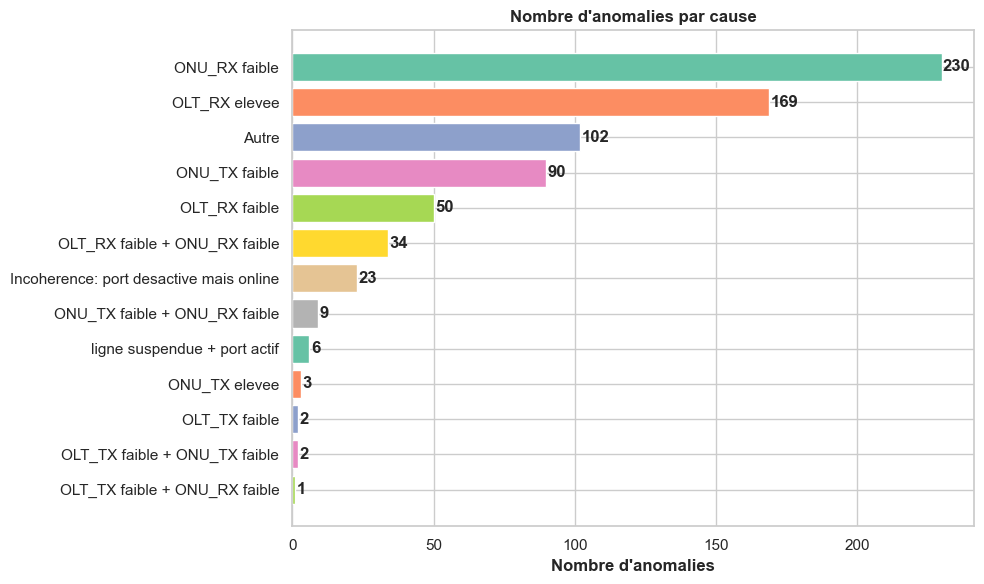

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

cause_counts = df_anom['Cause'].value_counts()

bars = plt.barh(
    cause_counts.index,
    cause_counts.values,
    color=sns.color_palette('Set2', len(cause_counts))
)

plt.xlabel("Nombre d'anomalies", fontweight='bold')
plt.title("Nombre d'anomalies par cause", fontweight='bold')

for bar, val in zip(bars, cause_counts.values):
    plt.text(
        val + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va='center',
        fontweight='bold'
    )

plt.gca().invert_yaxis()  
plt.tight_layout()
plt.show()

---
## PARTIE B — Localiser les Anomalies (Carte OLT / Port / ONU)

### Principe
```
Pour chaque cause identifiée en Partie A :
  → Sur quelle carte OLT les anomalies se concentrent-elles ?
  → Sur quel port ?
  → Quel ONU (abonné) est le plus touché ?
```

In [4]:
# ── Top 10 cartes OLT les plus touchées ──
print("=== TOP 10 CARTES OLT LES PLUS TOUCHÉES ===")
top_cartes = df_anom['ID_CARTE_OLT'].value_counts().head(10)
for carte, count in top_cartes.items():
    pct = count / len(df_anom) * 100
    print(f"  Carte OLT {carte:6d} : {count:3d} anomalies ({pct:.1f}%)")

print()

# ── Top 10 ports les plus touchés ──
print("=== TOP 10 PORTS LES PLUS TOUCHÉS ===")
top_ports = df_anom['NO_PORT'].value_counts().head(10)
for port, count in top_ports.items():
    pct = count / len(df_anom) * 100
    print(f"  Port {port:2d} : {count:3d} anomalies ({pct:.1f}%)")

print()

# ── Top 10 combinaisons Carte+Port ──
print("=== TOP 10 COMBINAISONS CARTE OLT + PORT ===")
combo = df_anom.groupby(['ID_CARTE_OLT','NO_PORT']).size().sort_values(ascending=False).head(10)
for (carte, port), count in combo.items():
    pct = count / len(df_anom) * 100
    print(f"  Carte {carte:6d} | Port {port:2d} → {count:3d} anomalies ({pct:.1f}%)")

=== TOP 10 CARTES OLT LES PLUS TOUCHÉES ===
  Carte OLT  20885 : 121 anomalies (16.8%)
  Carte OLT  20915 :  81 anomalies (11.2%)
  Carte OLT  20922 :  63 anomalies (8.7%)
  Carte OLT  20930 :  58 anomalies (8.0%)
  Carte OLT  20940 :  53 anomalies (7.4%)
  Carte OLT  20920 :  46 anomalies (6.4%)
  Carte OLT  20944 :  40 anomalies (5.5%)
  Carte OLT  20910 :  39 anomalies (5.4%)
  Carte OLT  20918 :  35 anomalies (4.9%)
  Carte OLT    170 :  34 anomalies (4.7%)

=== TOP 10 PORTS LES PLUS TOUCHÉS ===
  Port  5 : 113 anomalies (15.7%)
  Port  2 :  82 anomalies (11.4%)
  Port  0 :  81 anomalies (11.2%)
  Port  1 :  80 anomalies (11.1%)
  Port  3 :  45 anomalies (6.2%)
  Port  6 :  41 anomalies (5.7%)
  Port 14 :  37 anomalies (5.1%)
  Port  4 :  33 anomalies (4.6%)
  Port  9 :  32 anomalies (4.4%)
  Port 10 :  32 anomalies (4.4%)

=== TOP 10 COMBINAISONS CARTE OLT + PORT ===
  Carte  20885 | Port  5 →  34 anomalies (4.7%)
  Carte  20885 | Port  0 →  27 anomalies (3.7%)
  Carte  20885 | Po

### Heatmap — Carte OLT × Port (concentration des anomalies)

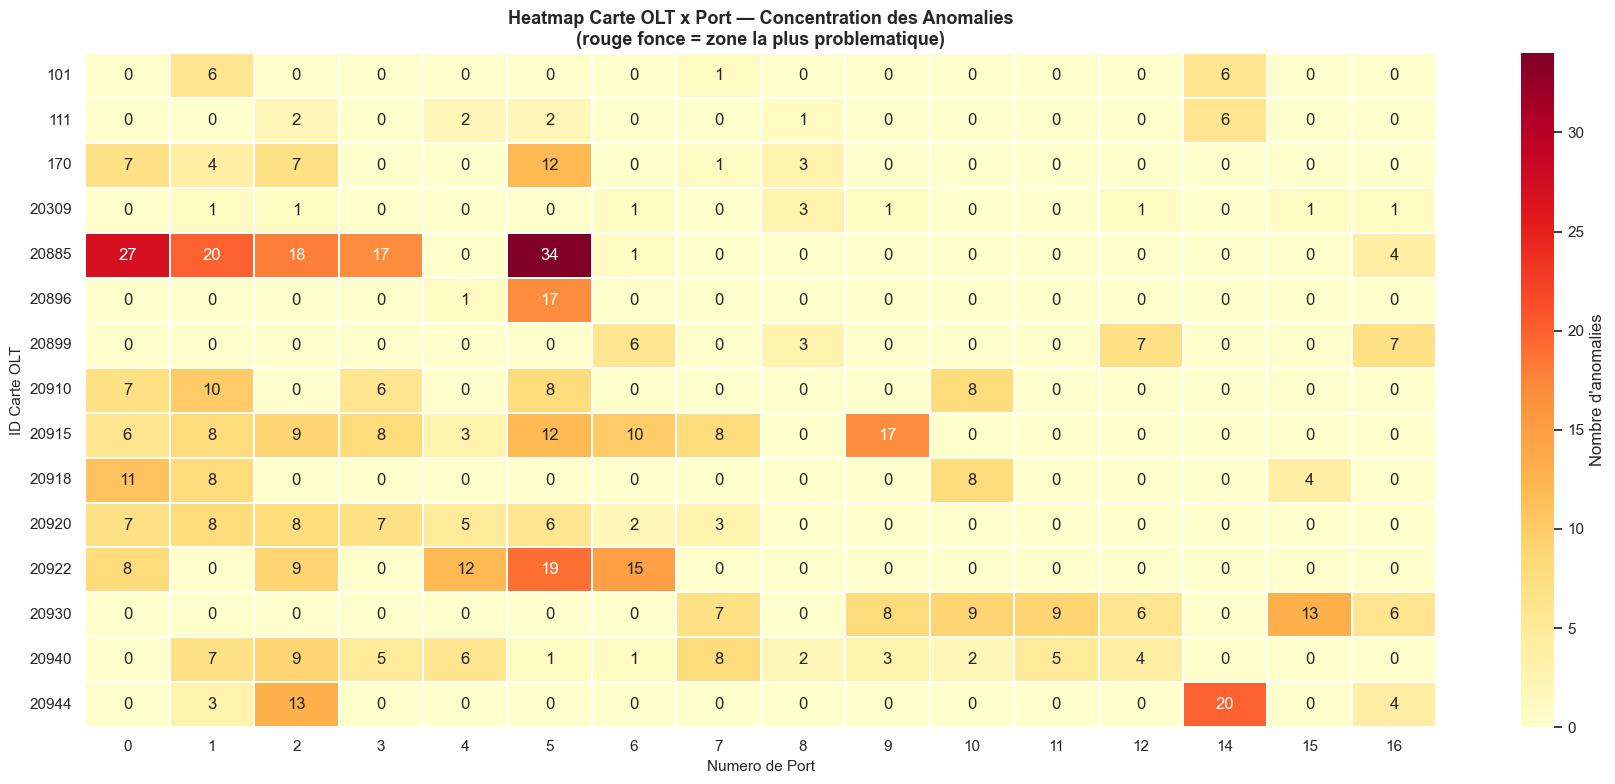

In [5]:
pivot = df_anom.pivot_table(
    index='ID_CARTE_OLT', columns='NO_PORT',
    aggfunc='size', fill_value=0
)

# Top 15 cartes et 16 ports pour lisibilité
top_c = df_anom['ID_CARTE_OLT'].value_counts().head(15).index
top_p = df_anom['NO_PORT'].value_counts().head(16).index
pivot_f = pivot.loc[pivot.index.isin(top_c), pivot.columns.isin(top_p)]

fig, ax = plt.subplots(figsize=(18, 8))
sns.heatmap(pivot_f, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=0.3, linecolor='white',
            cbar_kws={'label': "Nombre d'anomalies"}, ax=ax)
ax.set_title('Heatmap Carte OLT x Port — Concentration des Anomalies\n'
             '(rouge fonce = zone la plus problematique)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Numero de Port', fontsize=11)
ax.set_ylabel('ID Carte OLT', fontsize=11)
plt.tight_layout()
plt.show()

---
## PARTIE C — Regroupement K-Means (4 Clusters)

### Principe
```
On regroupe les 721 anomalies en 4 groupes distincts pour identifier les pannes structurelles :
  1. CARTE : Anomalies regroupées sur une même carte OLT.
  2. PORT  : Anomalies regroupées sur un même port PON.
  3. ADMIN : Anomalies liées à des incohérences administratives.
  4. AUTRE : Anomalies individuelles isolées.
```

In [ ]:
# ── 1. Flag Anomalie Administrative ──
def is_admin(row):
    if (row['F_SUSP'] == 1 and row['ADMIN_STATUS'] == 1) or \
       (row['ADMIN_STATUS'] == 0 and row['OPER_STATUS'] == 1):
        return 1
    return 0

df_anom['Anomalie_admin'] = df_anom.apply(is_admin, axis=1)

# ── 2. Taux de pannes par Carte et Port ──
# Note: Anomalie est le flag 0/1 (721 anomalies)
card_rate = df.groupby('ID_CARTE_OLT')['Anomalie'].mean().rename('card_fault_rate')
df_anom = df_anom.merge(card_rate, on='ID_CARTE_OLT', how='left')

port_rate = df.groupby(['ID_CARTE_OLT','NO_PORT'])['Anomalie'].mean().rename('port_fault_rate')
df_anom = df_anom.merge(port_rate, on=['ID_CARTE_OLT','NO_PORT'], how='left')

print("Features de regroupement calculées.")
print(df_anom[['ID_CARTE_OLT','NO_PORT','card_fault_rate','port_fault_rate','Anomalie_admin']].head())

In [ ]:
from sklearn.preprocessing import StandardScaler

features_list = [
    'Anomalie_admin',
    'card_fault_rate',
    'port_fault_rate',
    'OLT_POWER_TX',
    'OLT_RX_ONT_POWER',
    'ONU_POWER_TX',
    'ONU_POWER_RX',
    'OPER_STATUS'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_anom[features_list])

print(f"Données prêtes pour le clustering : {X_scaled.shape}")

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_anom['cluster_id'] = kmeans.fit_predict(X_scaled)

sil = silhouette_score(X_scaled, df_anom['cluster_id'])
print(f"Score de silhouette (4 clusters) : {sil:.3f}")

In [ ]:
# ── Interprétation des centroïdes pour nommer les clusters ──
centroids = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features_list
)

def map_cluster_name(row):
    if row['Anomalie_admin'] > 0.5: return 'admin'
    # On identifie le cluster 'carte' par le taux de panne carte maximum
    if row['card_fault_rate'] == centroids['card_fault_rate'].max(): return 'carte'
    # On identifie le cluster 'port' par le taux de panne port maximum (parmi les restants)
    if row['port_fault_rate'] == centroids['port_fault_rate'].max(): return 'port'
    return 'autre'

centroids['nom'] = centroids.apply(map_cluster_name, axis=1)
mapping = dict(zip(centroids.index, centroids['nom']))

df_anom['Cluster_Nom'] = df_anom['cluster_id'].map(mapping)

print("=== RÉPARTITION DES 721 ANOMALIES EN 4 GROUPES ===")
print(df_anom['Cluster_Nom'].value_counts())
print("\n=== CARACTÉRISTIQUES DES CENTROÏDES ===")
print(centroids[['nom', 'Anomalie_admin', 'card_fault_rate', 'port_fault_rate']])

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = df_anom['Cluster_Nom'].value_counts()
# Couleurs harmonieuses
colors = ['#e74c3c','#e67e22','#2980b9','#27ae60'] 

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Pie Chart
axes[0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=colors)
axes[0].set_title("Répartition des 721 anomalies", fontweight='bold')

# 2. Bar Chart
sns.barplot(x=counts.index, y=counts.values, ax=axes[1], palette=colors, hue=counts.index, legend=False)
axes[1].set_title("Nombre d'anomalies par type de panne", fontweight='bold')
axes[1].set_ylabel("Nb anomalies")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], 
    hue=df_anom['Cluster_Nom'], 
    palette=colors, 
    style=df_anom['Cluster_Nom'],
    s=60, alpha=0.8
)
plt.title("Visualisation PCA - Séparation des clusters", fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(title="Profil")
plt.show()

In [ ]:
# Export des anomalies avec leurs clusters pour le dashboard
df_anom.to_excel('anomalies_clustered.xlsx', index=False)
print("Fichier 'anomalies_clustered.xlsx' généré avec succès.")

---
## Conclusion
```
Le clustering a permis de diviser les 721 anomalies en 4 catégories opérationnelles.
Le dashboard peut maintenant afficher les priorités de maintenance :
 - Interventions sur cartes (pannes collectives)
 - Nettoyage de ports PON
 - Corrections administratives
```